In [64]:
from pathlib import Path
import pandas as pd

SUBSAMPLE = "up0.001_ip0.001"
base = Path(f"../datasets/VK-LSVD/subsamples/{SUBSAMPLE}")

train_files = sorted(
    (base / "train").glob("week_*.parquet"),
    key=lambda p: int(p.stem.split("_")[1]),   # сортировка по номеру недели
)
train = pd.concat(
    [pd.read_parquet(f).assign(week=int(f.stem.split("_")[1]))   # week_07 → 7
     for f in train_files],
    ignore_index=True,
)
train["week"] = train["week"].astype("int8")
val  = pd.read_parquet(base / "validation" / "week_25.parquet")
test = pd.read_parquet(base / "test" / "week_26.parquet")

print(train.shape, val.shape, test.shape)
print(train.dtypes)
print(train.head())
print(f"{train.memory_usage(deep=True).sum() / 1e9:.2f} GB")

(47068641, 13) (519839, 12) (387800, 12)
user_id            uint32
item_id            uint32
place               uint8
platform            uint8
agent               uint8
timespent           uint8
like                 bool
dislike              bool
share                bool
bookmark             bool
click_on_author      bool
open_comments        bool
week                 int8
dtype: object
     user_id    item_id  place  platform  agent  timespent   like  dislike  \
0  141827770  160593626      1         1      1         56  False    False   
1  468779351  327484273      1         0      0          1  False    False   
2  494341617  402842289      1         0      0         11  False    False   
3  453833313  102672169      0         0      0         45  False    False   
4  154047442  139795075      1         0      0         39  False    False   

   share  bookmark  click_on_author  open_comments  week  
0  False     False            False          False     0  
1  False     False  

In [65]:
from pathlib import Path
import pandas as pd

META = Path(r"d:\SASRec_BERT4Rec_VK_LSVD\datasets\VK-LSVD\metadata")   # ваша папка

items_meta = pd.read_parquet(META / "items_metadata.parquet")
users_meta = pd.read_parquet(META / "users_metadata.parquet")

print(items_meta.shape, users_meta.shape)
print(items_meta.dtypes, "\n")
print(users_meta.dtypes, "\n")
print(items_meta.head())
print(users_meta.head())
print(f"items: {items_meta.memory_usage(deep=True).sum()/1e9:.2f} GB, "
      f"users: {users_meta.memory_usage(deep=True).sum()/1e9:.2f} GB")

(19627601, 4) (10000000, 5)
item_id                    uint32
author_id                  uint32
duration                    uint8
train_interactions_rank    uint32
dtype: object 

user_id                    uint32
age                         uint8
gender                      uint8
geo                         uint8
train_interactions_rank    uint32
dtype: object 

     item_id  author_id  duration  train_interactions_rank
0   88620250        558        11                 19270549
1  218436133        558        14                 19264036
2  436082061        558        14                 19264046
3  344447950        558        15                 19181835
4   62832841        558        17                 19184376
    user_id  age  gender  geo  train_interactions_rank
0   4927034   18       1    0                  4522102
1  11129916   18       1    0                  2331631
2  13058776   18       1    0                  8896963
3  15412654   18       1    0                  9839976
4  16

In [66]:
train = train.drop_duplicates(subset=['user_id', 'item_id'])

In [67]:
for col in train.columns:
    if train[col].dtype in ("bool", "boolean"):
        print(train[col].value_counts(dropna=False), "\n")

like
False    46614807
True       453834
Name: count, dtype: int64 

dislike
False    47050071
True        18570
Name: count, dtype: int64 

share
False    46942492
True       126149
Name: count, dtype: int64 

bookmark
False    47049427
True        19214
Name: count, dtype: int64 

click_on_author
False    47017350
True        51291
Name: count, dtype: int64 

open_comments
False    46354108
True       714533
Name: count, dtype: int64 



In [68]:
for col in train.columns:
    if train[col].dtype in ("bool", "boolean"):
        train[col] = train[col].astype("int8")

In [69]:
train.head(10)

,user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments,week
0,141827770,160593626,1,1,1,56,0,0,0,0,0,0,0
1,468779351,327484273,1,0,0,1,0,0,0,0,0,0,0
2,494341617,402842289,1,0,0,11,0,0,0,0,0,0,0
3,453833313,102672169,0,0,0,45,0,0,0,0,0,0,0
4,154047442,139795075,1,0,0,39,0,0,0,0,0,0,0
5,330326695,232077218,1,0,0,57,0,0,0,0,0,0,0
6,179539924,199030149,1,0,0,6,0,0,0,0,0,0,0
7,202161065,96086330,2,0,0,2,0,0,0,0,0,0,0
8,452519119,36443486,1,0,0,23,1,0,0,0,0,1,0
9,340518162,327484273,1,0,0,1,0,0,0,0,0,0,0


In [70]:
dense = len(train) / (len(train['user_id'].unique()) * len(train['item_id'].unique()))
dense

0.23980355104952109

In [71]:
import matplotlib.pyplot as plt
import numpy as np

user_count = train.groupby('user_id').size()

print(user_count.describe())
print(user_count.quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

count    10000.000000
mean      4706.864100
std       1342.719324
min        288.000000
25%       3783.000000
50%       4749.000000
75%       5661.000000
max       9153.000000
dtype: float64
0.25    3783.00
0.50    4749.00
0.75    5661.00
0.90    6400.10
0.95    6840.00
0.99    7675.06
dtype: float64


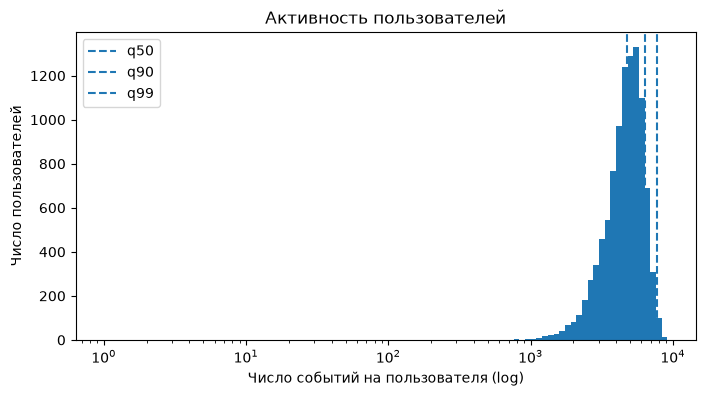

In [72]:
bins = np.logspace(0, np.log10(user_count.max()), 100)   # корзины равной ширины в лог-шкале

plt.figure(figsize=(8, 4))
plt.hist(user_count, bins=bins)
plt.xscale("log")
plt.xlabel("Число событий на пользователя (log)")
plt.ylabel("Число пользователей")
plt.title("Активность пользователей")
for q in [0.5, 0.9, 0.99]:
    plt.axvline(user_count.quantile(q), linestyle="--", label=f"q{int(q*100)}")
plt.legend()
plt.show()

In [86]:
top_10 = user_count.sort_values(ascending=False).head(10).index.tolist()
top_count = user_count.sort_values(ascending=False).head(10).values.tolist()

In [82]:
top_10

[144038149,
 129099524,
 312664261,
 493977493,
 403474601,
 93581770,
 164164874,
 486085406,
 373875823,
 61966005]

In [87]:
top = pd.DataFrame({
    "user_id": top_10,
    "count": top_count
    }).set_index("user_id")


In [90]:
count_week = len(train['week'].unique())

In [110]:
top["count_per_week"] = top["count"] / count_week
top['count_per_hour'] = top['count_per_week'] / (24 * 7)
top['likes'] = train[train['like'] == 1].groupby('user_id').size().reindex(top.index, fill_value=0)
top['watch_time'] = train.groupby('user_id')['timespent'].sum().reindex(top.index, fill_value=0)
top['watch_time'] = top['watch_time'] / top['count']   # среднее время просмотра на событие 

In [111]:
top

,count,count_per_week,count_per_hour,likes,watch_time
user_id,,,,,
144038149,9153,366.12,2.179286,0,10.129138
129099524,8965,358.60,2.134524,3,11.492917
312664261,8791,351.64,2.093095,6,10.979297
493977493,8696,347.84,2.070476,0,7.440892
403474601,8611,344.44,2.050238,1,11.019742
93581770,8527,341.08,2.030238,3,11.296235
164164874,8502,340.08,2.024286,0,11.355681
486085406,8447,337.88,2.011190,3,18.340831
373875823,8410,336.40,2.002381,0,7.780143


In [118]:
top_full = user_count.sort_values(ascending=False).values.tolist()

In [123]:
top_1p = sum(top_full[:int(len(top_full) * 0.01)])
top_10p = sum(top_full[:int(len(top_full) * 0.1)])

In [125]:
print(f"Топ 1% пользователей: {top_1p} событий, {top_1p / sum(user_count.values.tolist()) * 100:.2f}% от всех событий")
print(f"Топ 10% пользователей: {top_10p} событий, {top_10p / sum(user_count.values.tolist()) * 100:.2f}% от всех событий")

Топ 1% пользователей: 798838 событий, 1.70% от всех событий
Топ 10% пользователей: 6969805 событий, 14.81% от всех событий


Подвыборка содержит только самых активных пользователей: ~4700 событий на пользователя за 25 недель (~50 в день), распределение почти симметричное (mean ≈ median). Активность равномерная: топ-10% пользователей дают 14,8% событий, поэтому веса пользователей не нужны. Явных ботов нет. Лайки встречаются реже 0,1% → позитив строим по watch time. max_len: старт 200, финальное значение выбираем по валидации.

In [126]:
video_count = train.groupby('item_id').size()

item_id
66761         510
71482         596
99494        1111
150686       2902
182273        922
             ... 
607900487    1167
607918712    2480
607945053    1983
608022678    4409
608034240    1737
Length: 19628, dtype: int64

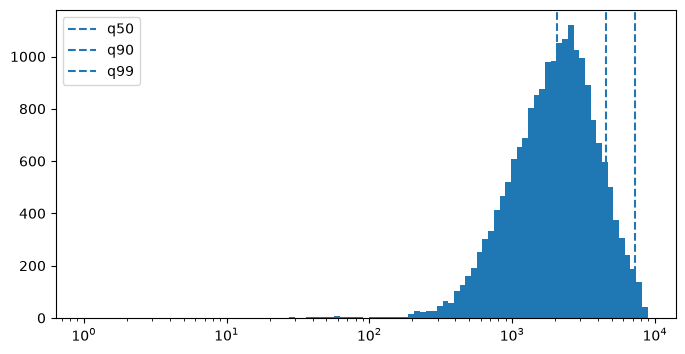

In [127]:
bins_v = np.logspace(0, np.log10(video_count.max()), 100)   # корзины равной ширины в лог-шкале

plt.figure(figsize=(8, 4))
plt.hist(video_count, bins=bins_v)
plt.xscale("log")
for q in [0.5, 0.9, 0.99]:
    plt.axvline(video_count.quantile(q), linestyle="--", label=f"q{int(q*100)}")
plt.legend()
plt.show()

In [129]:
top_video = video_count.sort_values(ascending=False)
full_video_count = sum(video_count.sort_values(ascending=False).values.tolist())
top_1p_v = sum(top_video[:int(len(top_video) * 0.01)])
top_10p_v = sum(top_video[:int(len(top_video) * 0.1)])
print(f"Топ 1% видео: {top_1p_v} событий, {top_1p_v / full_video_count * 100:.2f}% от всех событий")
print(f"Топ 10% видео: {top_10p_v} событий, {top_10p_v / full_video_count * 100:.2f}% от всех событий")

Топ 1% видео: 1522682 событий, 3.24% от всех событий
Топ 10% видео: 11283804 событий, 23.97% от всех событий


In [130]:
c = 0
for i in top_video.values:
    if i <= 5:
        c += 1
print(f"Видео с 5 и менее событиями: {c}, {c / len(top_video) * 100:.2f}% от всех видео")

Видео с 5 и менее событиями: 0, 0.00% от всех видео


In [ ]:
check = train.groupby("item_id")["user_id"].agg(["size", "nunique"])

In [133]:
for i in check.itertuples():
    if i.size != i.nunique:
        print(f"Видео {i.Index} имеет {i.size} событий, но только {i.nunique} уникальных пользователей")

            n_items  mean_epw  median_epw
first_week                               
0              4026     82.56       71.72
1               739     88.17       77.17
2               698    101.74       90.80
3               777    110.68      101.14
4               735    110.32       98.43
5               668    115.81      100.07
6               929    133.37      117.21
7               848    134.09      113.92
8               882    151.77      130.03
9              1049    178.42      146.00
10              781    175.03      153.07
11              850    175.56      147.43
12              720    192.82      163.96
13              933    198.62      172.08
14              738    224.06      192.00
15              768    241.26      204.00
16              698    294.68      263.39
17              590    333.38      291.31
18              416    381.02      330.43
19              325    384.72      324.17
20              396    493.74      406.40
21              325    636.02     

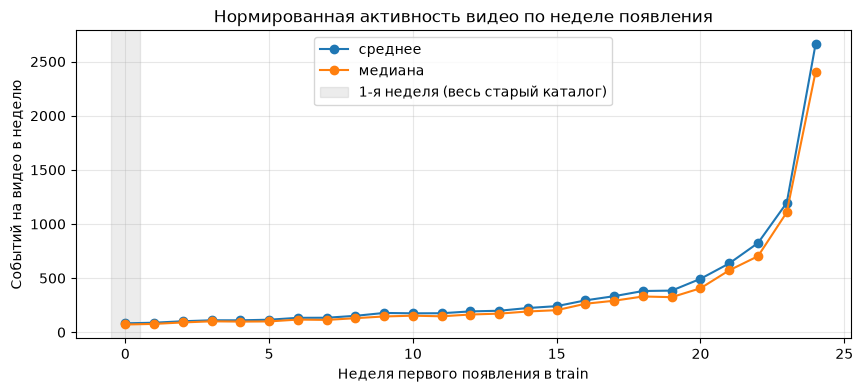

In [136]:
import matplotlib.pyplot as plt

first_train_week = train["week"].min()
last_train_week = train["week"].max()

item_stats = train.groupby("item_id").agg(
    first_week=("week", "min"),
    n_events=("user_id", "size"),
)

# сколько недель видео могло набирать события (включая неделю появления)
item_stats["weeks_available"] = last_train_week - item_stats["first_week"] + 1
item_stats["events_per_week"] = item_stats["n_events"] / item_stats["weeks_available"]

by_week = item_stats.groupby("first_week").agg(
    n_items=("events_per_week", "size"),
    mean_epw=("events_per_week", "mean"),
    median_epw=("events_per_week", "median"),
)
print(by_week.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_week.index, by_week["mean_epw"], marker="o", label="среднее")
ax.plot(by_week.index, by_week["median_epw"], marker="o", label="медиана")
ax.axvspan(first_train_week - 0.5, first_train_week + 0.5,
           color="grey", alpha=0.15, label="1-я неделя (весь старый каталог)")
ax.set_xlabel("Неделя первого появления в train")
ax.set_ylabel("Событий на видео в неделю")
ax.set_title("Нормированная активность видео по неделе появления")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

    n_events  n_items  mean_events  mean_events_active_only
0   12947052    15602      829.833                  829.833
1   10584835    15495      683.113                  726.133
2    4041192    15213      265.641                  324.672
3    1735966    14865      116.782                  184.461
4    1350594    14540       92.888                  157.890
5    1105439    14144       78.156                  137.202
6     952955    13819       68.960                  127.010
7     843989    13403       62.970                  120.141
8     747561    12813       58.344                  114.341
9     623167    12115       51.438                  105.568
10    579180    11347       51.043                  107.935
11    516130    10609       48.650                  103.599
12    484990     9676       50.123                  105.893
13    409467     8956       45.720                   96.618
14    371904     8106       45.880                   97.306
15    357730     7325       48.837      

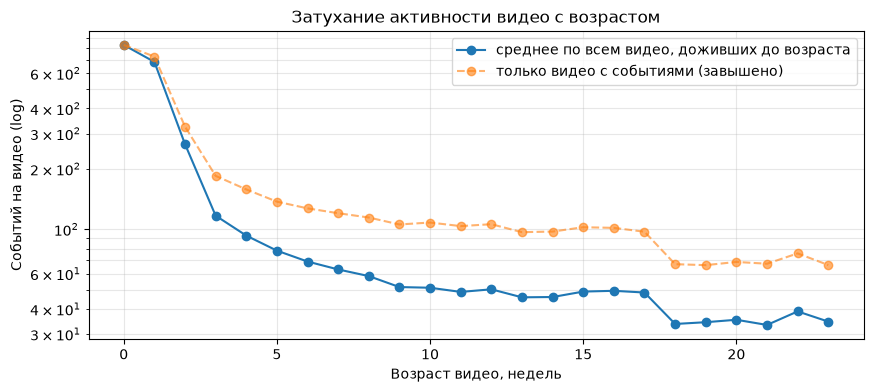

In [137]:
import numpy as np
import matplotlib.pyplot as plt

first_train_week = train["week"].min()   # 0, если недели нумеруются с нуля
last_train_week = train["week"].max()

# 1. возраст видео в момент каждого события
first_week = train.groupby("item_id")["week"].min()
ev = train[["item_id", "week"]].copy()
ev["first_week"] = ev["item_id"].map(first_week)
ev["age"] = (ev["week"] - ev["first_week"]).astype("int16")

# 2. убираем видео, появившиеся в первую неделю train (их настоящий возраст неизвестен)
ev = ev[ev["first_week"] != first_train_week]
fw = first_week[first_week != first_train_week]

# 3. события на каждом возрасте / число видео, которые могли дожить до этого возраста
events_by_age = ev.groupby("age").size()
ages = np.arange(last_train_week - fw.min() + 1)
max_age = last_train_week - fw                      # максимальный наблюдаемый возраст каждого видео
eligible = pd.Series([(max_age >= a).sum() for a in ages], index=ages)

age_stats = pd.DataFrame({
    "n_events": events_by_age.reindex(ages, fill_value=0),
    "n_items": eligible,
})
age_stats["mean_events"] = age_stats["n_events"] / age_stats["n_items"]

# для сравнения: «наивное» среднее только по видео, активным на этом возрасте
age_stats["mean_events_active_only"] = (
    ev.groupby(["item_id", "age"]).size().groupby("age").mean()
)
print(age_stats.round(3))

# 4. график с логарифмической осью Y
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(age_stats.index, age_stats["mean_events"], marker="o",
        label="среднее по всем видео, доживших до возраста")
ax.plot(age_stats.index, age_stats["mean_events_active_only"], marker="o",
        linestyle="--", alpha=0.6, label="только видео с событиями (завышено)")
ax.set_yscale("log")
ax.set_xlabel("Возраст видео, недель")
ax.set_ylabel("Событий на видео (log)")
ax.set_title("Затухание активности видео с возрастом")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WT = "timespent"   # watch time, 0–255
SIGNALS = ["like", "dislike", "share", "bookmark", "open_comments", "click_on_author"]

items = pd.read_parquet("../datasets/VK-LSVD/metadata/items_metadata.parquet")  # путь поправьте под себя

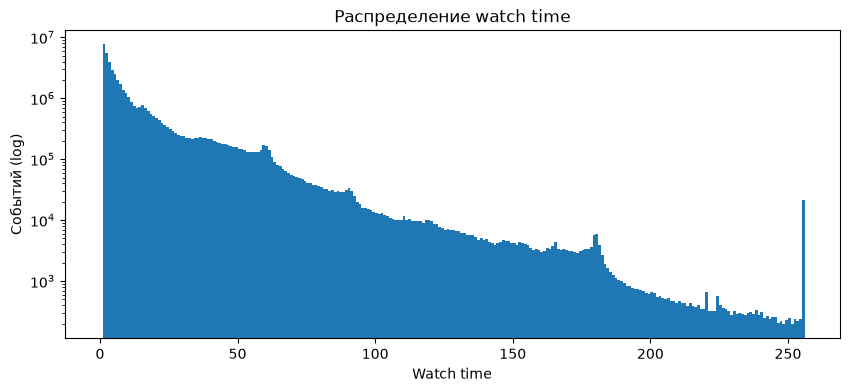

0.01      1.0
0.05      1.0
0.10      1.0
0.25      2.0
0.50      6.0
0.75     18.0
0.90     44.0
0.95     60.0
0.99    108.0
Name: timespent, dtype: float64
Доля watch time = 0:   0.00%
Доля watch time = 255: 0.05%


In [139]:
wt = train[WT]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(wt, bins=256, range=(0, 256))
ax.set_yscale("log")
ax.set_xlabel("Watch time")
ax.set_ylabel("Событий (log)")
ax.set_title("Распределение watch time")
plt.show()

print(wt.quantile([0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
print(f"Доля watch time = 0:   {(wt == 0).mean():.2%}")
print(f"Доля watch time = 255: {(wt == 255).mean():.2%}")

Не нашлось длительности: 0.00%


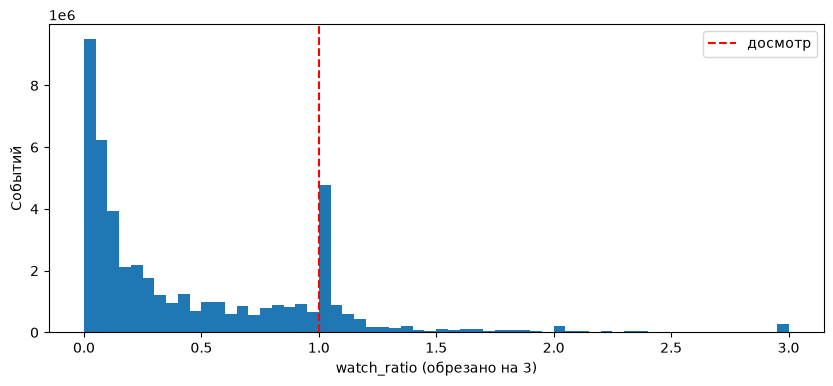

Доля watch_ratio ≥ 1: 19.49%


In [140]:
duration = items.set_index("item_id")["duration"]
train["duration"] = train["item_id"].map(duration)       # map экономнее по памяти, чем merge
train["watch_ratio"] = train[WT] / train["duration"].replace(0, np.nan)

print(f"Не нашлось длительности: {train['duration'].isna().mean():.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(train["watch_ratio"].clip(upper=3).dropna(), bins=60, range=(0, 3))
ax.axvline(1, color="red", linestyle="--", label="досмотр")
ax.set_xlabel("watch_ratio (обрезано на 3)")
ax.set_ylabel("Событий")
ax.legend()
plt.show()

print(f"Доля watch_ratio ≥ 1: {(train['watch_ratio'] >= 1).mean():.2%}")

In [141]:
bins = [0, 15, 30, 60, 120, np.inf]
labels = ["0–15", "15–30", "30–60", "60–120", "120+"]
train["dur_bin"] = pd.cut(train["duration"], bins=bins, labels=labels, right=False)

dur_stats = train.groupby("dur_bin", observed=True).agg(
    n_events=(WT, "size"),
    mean_watch_time=(WT, "mean"),
    mean_watch_ratio=("watch_ratio", "mean"),
    share_full=("watch_ratio", lambda x: (x >= 1).mean()),
)
print(dur_stats.round(3))

         n_events  mean_watch_time  mean_watch_ratio  share_full
dur_bin                                                         
0–15      9084197            7.124             0.813       0.352
15–30    10136693           10.013             0.501       0.218
30–60    16152447           18.032             0.396       0.162
60–120    9672343           22.045             0.297       0.104
120+      2022961           28.743             0.191       0.070


In [142]:
WT = "timespent"
SIGNALS = ["like", "dislike", "share", "bookmark", "open_comments", "click_on_author"]

# watch_ratio, если ещё не считали в 5.2
if "watch_ratio" not in train.columns:
    items = pd.read_parquet("../datasets/VK-LSVD/metadata/items_metadata.parquet")
    duration = items.set_index("item_id")["duration"]
    train["watch_ratio"] = train[WT] / train["item_id"].map(duration).replace(0, np.nan)

# 1. доля событий с каждым сигналом
signal_share = train[SIGNALS].astype(bool).mean().sort_values(ascending=False)
print((signal_share * 100).round(3).rename("% событий"))

# 2. watch ratio по группам
groups = {
    "с лайком":    train["like"] == 1,
    "без лайка":   train["like"] == 0,
    "с дизлайком": train["dislike"] == 1,
}
ratio_by_signal = pd.DataFrame({
    name: {
        "n_events": mask.sum(),
        "mean_watch_ratio": train.loc[mask, "watch_ratio"].mean(),
        "median_watch_ratio": train.loc[mask, "watch_ratio"].median(),
    }
    for name, mask in groups.items()
}).T
print(ratio_by_signal.round(3))

open_comments      1.518
like               0.964
share              0.268
click_on_author    0.109
bookmark           0.041
dislike            0.039
Name: % событий, dtype: float64
               n_events  mean_watch_ratio  median_watch_ratio
с лайком       453834.0             1.084               1.000
без лайка    46614807.0             0.464               0.225
с дизлайком     18570.0             0.587               0.342
